# Tuần 8 – Tích hợp ByteTrack với YOLO (Đỗ Xuân Bách)

**Mục tiêu:** tích hợp thuật toán theo dõi đa đối tượng ByteTrack với model YOLO để gán **Tracking ID ổn định** cho từng xe trong video.

**Sản phẩm:**
- `vehicle_tracker.py`: module dùng chung cho nhóm (đếm xe qua vạch ảo, luồng video camera, model ONNX)
- `trackers/bytetrack_tuned.yaml`: cấu hình ByteTrack đã tinh chỉnh (module tự dùng)
- `output/`: video có vẽ ID, ảnh chụp, bảng số liệu, biểu đồ
- `Báo cáo tuần 8.md`: tự sinh ở cuối notebook

**Cách chạy:** chép video giao thông vào `tuan8/videos/`, chọn kernel `.venv` của dự án rồi *Run all*.

In [1]:
%pip install -q ultralytics pandas "lap>=0.5.12"

Note: you may need to restart the kernel to use updated packages.


## 1. Cấu hình

In [2]:
import sys, time, shutil
from collections import defaultdict, deque
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ultralytics
import yaml

sys.path.insert(0, str(Path.cwd()))
from vehicle_tracker import VehicleTracker, draw_tracks, open_writer

# Notebook nằm trong tuan8/; models/ ở thư mục gốc, dùng chung cho các tuần
ROOT = Path("..") if Path("../train.py").exists() else Path(".")
WEIGHTS = ROOT / "models/yolo11s_best.pt"  # model được chọn ở tuần 7
VIDEO_DIR = Path("videos")
TRACKER_DIR = Path("trackers")
OUT_DIR = Path("output")
for d in (TRACKER_DIR, OUT_DIR / "snapshots"):
    d.mkdir(parents=True, exist_ok=True)
REPORT_PATH = Path("Báo cáo tuần 8.md")

TUNE_MAX_SECONDS = 60     # khi so sánh cấu hình chỉ dùng tối đa 60 giây đầu mỗi video cho nhanh
MIN_TRACK_SECONDS = 0.5   # track tồn tại ngắn hơn mức này coi là "track vụn"
BREAK_GAP_SECONDS = 2.0   # ID mới xuất hiện gần chỗ ID cũ vừa mất trong khoảng này -> nghi bị đổi ID
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None

assert WEIGHTS.exists(), f"Không tìm thấy {WEIGHTS} – chạy notebook tuần 7 trước"
videos = sorted(p for p in VIDEO_DIR.iterdir() if p.suffix.lower() in {".mp4", ".avi", ".mov", ".mkv"})
assert videos, "Chưa có video – chép video giao thông vào tuan8/videos/ rồi chạy lại"


def video_meta(path):
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    meta = {"Video": path.name,
            "Độ phân giải": f"{int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))}×{int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))}",
            "FPS": round(fps, 1), "Số frame": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
            "Thời lượng (giây)": round(cap.get(cv2.CAP_PROP_FRAME_COUNT) / fps, 1)}
    cap.release()
    return meta


video_tbl = pd.DataFrame([video_meta(v) for v in videos]).set_index("Video")
video_tbl.to_csv(OUT_DIR / "video.csv")
display(video_tbl)

,Độ phân giải,FPS,Số frame,Thời lượng (giây)
Video,,,,
FREE STOCK FOOTAGE - Heavy traffic.mp4,1920×1080,25.0,283,11.3


## 2. Các cấu hình ByteTrack đưa vào so sánh

ByteTrack ghép detection với các track đang có theo 2 bước: (1) detection có điểm cao (≥ `track_high_thresh`) được ghép trước theo IoU với vị trí dự đoán của track (bộ lọc Kalman); (2) detection điểm thấp (≥ `track_low_thresh`) được dùng để **nối lại các xe bị che một phần**. Detection điểm cao không ghép được và ≥ `new_track_thresh` sẽ tạo ID mới. Track bị mất được giữ `track_buffer` frame trước khi xóa.

Các cấu hình thử nhắm vào nguyên nhân đổi ID thường gặp ở giao thông Việt Nam (xe máy dày đặc, che khuất nhau – xem tuần 6):
| Cấu hình | Thay đổi so với mặc định | Mục đích |
|---|---|---|
| A | – | Mốc so sánh |
| B | `track_buffer` 30 → 60 | Giữ ID lâu hơn khi xe bị che |
| C | B + `new_track_thresh` 0.25 → 0.4 | Hạn chế tạo ID mới từ detection yếu |
| D | C + `track_buffer` 90, `match_thresh` 0.8 → 0.9 | Ghép cặp nới lỏng hơn cho xe chạy nhanh / bị che lâu |

In [3]:
BASE = yaml.safe_load(open(Path(ultralytics.__file__).parent / "cfg/trackers/bytetrack.yaml", encoding="utf-8"))
CONFIGS = {
    "A. Mặc định": {},
    "B. Giữ ID lâu hơn": {"track_buffer": 60},
    "C. B + hạn chế ID mới": {"track_buffer": 60, "new_track_thresh": 0.4},
    "D. C + ghép cặp nới lỏng": {"track_buffer": 90, "new_track_thresh": 0.4, "match_thresh": 0.9},
}
cfg_paths, cfg_rows = {}, []
for name, override in CONFIGS.items():
    cfg = {**BASE, **override}
    path = TRACKER_DIR / f"bytetrack_{name[0].lower()}.yaml"
    with open(path, "w", encoding="utf-8") as f:
        yaml.safe_dump(cfg, f, sort_keys=False)
    cfg_paths[name] = path
    cfg_rows.append({"Cấu hình": name, **{k: v for k, v in cfg.items() if k != "tracker_type"}})
cfg_tbl = pd.DataFrame(cfg_rows).set_index("Cấu hình")
display(cfg_tbl)

,track_high_thresh,track_low_thresh,new_track_thresh,track_buffer,match_thresh,fuse_score
Cấu hình,,,,,,
A. Mặc định,0.25,0.1,0.25,30,0.8,True
B. Giữ ID lâu hơn,0.25,0.1,0.25,60,0.8,True
C. B + hạn chế ID mới,0.25,0.1,0.40,60,0.8,True
D. C + ghép cặp nới lỏng,0.25,0.1,0.40,90,0.9,True


## 3. Hàm chạy tracking và đo độ ổn định ID

Video không có nhãn tracking chuẩn (ground truth), nên độ ổn định ID được đo bằng các **chỉ số gián tiếp**:
- **Số ID**: càng gần số xe thật càng tốt; bị đổi ID thì số ID tăng.
- **Độ dài track trung vị**: thời gian một ID tồn tại; càng dài càng ổn định.
- **Track vụn**: tỉ lệ ID tồn tại < 0.5 giây, thường do mất dấu rồi tạo ID mới hoặc do detection nhiễu.
- **Nghi đổi ID**: một ID biến mất *giữa khung hình* (không phải đi ra mép), và trong 2 giây có một ID mới *cùng lớp* xuất hiện ngay gần đó → nhiều khả năng là cùng một xe bị gán ID mới.
- **Nhảy vị trí bất thường**: giữa 2 lần xuất hiện liên tiếp, tâm box của một ID dịch xa hơn kích thước box → nhiều khả năng ID bị ghép nhầm sang xe khác (lỗi gộp nhầm, ngược với đổi ID).
- **Lỗi ID / 100 xe** = (nghi đổi ID + nhảy bất thường) / số xe ước lượng × 100. Dùng để chọn cấu hình, vì giảm lỗi đổi ID bằng cách ghép cặp nới lỏng thường làm tăng lỗi gộp nhầm.
- **ID bị đổi lớp**: tỉ lệ ID có lúc bị model gán lớp khác (vd. truck ↔ car); module làm mượt bằng bỏ phiếu 30 frame.

In [4]:
COLS = ["frame", "id", "cls", "raw_cls", "conf", "x1", "y1", "x2", "y2"]


def run_tracking(video, cfg_path, max_frames=None, writer_path=None, snapshot_frames=()):
    tracker = VehicleTracker(WEIGHTS, cfg_path)
    cap = cv2.VideoCapture(str(video))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = open_writer(writer_path, fps, (w, h)) if writer_path else None
    trails = defaultdict(lambda: deque(maxlen=int(fps)))
    rows, n, t_proc, seen = [], 0, 0.0, set()
    while max_frames is None or n < max_frames:
        ok, frame = cap.read()
        if not ok:
            break
        t0 = time.perf_counter()
        tracks = tracker.update(frame)
        t_proc += time.perf_counter() - t0
        for tr in tracks:
            rows.append((n, tr.track_id, tr.cls, tr.raw_cls, tr.conf, *tr.box))
            seen.add(tr.track_id)
        if writer is not None:
            vis = draw_tracks(frame, tracks, trails)
            cv2.putText(vis, f"frame {n} | dang theo doi: {len(tracks)} | tong ID: {len(seen)}", (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
            writer.write(vis)
            if n in snapshot_frames:
                cv2.imwrite(str(OUT_DIR / "snapshots" / f"{Path(video).stem}_f{n}.jpg"), vis)
        n += 1
    cap.release()
    if writer is not None:
        writer.release()
    info = dict(frames=n, fps_video=fps, w=w, h=h, fps_proc=n / t_proc if t_proc else np.nan)
    return pd.DataFrame(rows, columns=COLS), info


def track_metrics(df, info):
    fps, W, H = info["fps_video"], info["w"], info["h"]
    if df.empty:
        return {"Số ID": 0, "FPS xử lý": round(info["fps_proc"], 1)}
    g = df.groupby("id")
    span = g.frame.max() - g.frame.min() + 1
    main_cls = g.cls.agg(lambda s: s.mode().iloc[0])
    first = df.loc[g.frame.idxmin()].set_index("id")
    last = df.loc[g.frame.idxmax()].set_index("id")
    margin, gap = 0.03, BREAK_GAP_SECONDS * fps
    breaks = 0
    for tid, r in last.iterrows():
        if r.frame >= info["frames"] - 1:
            continue  # vẫn còn đến cuối video
        if r.x1 < margin * W or r.y1 < margin * H or r.x2 > (1 - margin) * W or r.y2 > (1 - margin) * H:
            continue  # xe đi ra khỏi khung hình
        cand = first[(first.frame > r.frame) & (first.frame <= r.frame + gap)]
        if cand.empty:
            continue
        dist = np.hypot((cand.x1 + cand.x2) / 2 - (r.x1 + r.x2) / 2, (cand.y1 + cand.y2) / 2 - (r.y1 + r.y2) / 2)
        size = max(r.x2 - r.x1, r.y2 - r.y1)
        if ((dist < 1.5 * size) & (main_cls[cand.index] == main_cls[tid])).any():
            breaks += 1
    # Nhảy vị trí bất thường: giữa 2 lần xuất hiện liên tiếp, tâm box của cùng một ID dịch xa hơn kích thước box
    # -> thường là ID bị ghép nhầm sang xe khác (lỗi gộp nhầm)
    d = df.sort_values(["id", "frame"])
    cx, cy = (d.x1 + d.x2) / 2, (d.y1 + d.y2) / 2
    size = np.maximum(d.x2 - d.x1, d.y2 - d.y1)
    same = d.id.eq(d.id.shift())
    move = np.hypot(cx - cx.shift(), cy - cy.shift())
    jumps = int((same & (move > np.maximum(size, size.shift()))).sum())
    n_ids = len(span)
    return {
        "Số ID": n_ids,
        "Độ dài track trung vị (giây)": round(span.median() / fps, 2),
        "Track vụn (%)": round((span < MIN_TRACK_SECONDS * fps).mean() * 100, 1),
        "Nghi đổi ID": breaks,
        "Nghi đổi ID / 100 ID": round(breaks / n_ids * 100, 1),
        "Nhảy vị trí bất thường": jumps,
        "Nhảy bất thường / 100 ID": round(jumps / n_ids * 100, 1),
        "ID bị đổi lớp – trước làm mượt (%)": round((g.raw_cls.nunique() > 1).mean() * 100, 1),
        "ID bị đổi lớp – sau làm mượt (%)": round((g.cls.nunique() > 1).mean() * 100, 1),
        "FPS xử lý": round(info["fps_proc"], 1),
    }

## 4. So sánh các cấu hình

In [5]:
# Chạy khởi động để GPU nạp xong, tránh cấu hình chạy đầu tiên bị đo FPS thấp
run_tracking(videos[0], cfg_paths[next(iter(CONFIGS))], max_frames=30)

rows, tune_runs = [], {}
for video in videos:
    max_frames = int(TUNE_MAX_SECONDS * video_tbl.loc[video.name, "FPS"])
    for name, path in cfg_paths.items():
        df, info = run_tracking(video, path, max_frames=max_frames)
        tune_runs[(video.name, name)] = (df, info)
        rows.append({"Video": video.name, "Cấu hình": name, **track_metrics(df, info)})
        print(f"{video.name} | {name}: xong")
tune = pd.DataFrame(rows)
tune.to_csv(OUT_DIR / "so_sanh_cau_hinh_theo_video.csv", index=False)

# Gộp các video: cộng số đếm, lấy trung bình các tỉ lệ
SUM_COLS = ["Số ID", "Nghi đổi ID", "Nhảy vị trí bất thường"]
summary = tune.groupby("Cấu hình", sort=False).agg(
    {c: ("sum" if c in SUM_COLS else "mean") for c in tune.columns if c not in ("Video", "Cấu hình")})
summary["Nghi đổi ID / 100 ID"] = (summary["Nghi đổi ID"] / summary["Số ID"] * 100).round(1)
summary["Nhảy bất thường / 100 ID"] = (summary["Nhảy vị trí bất thường"] / summary["Số ID"] * 100).round(1)
# Tổng lỗi ID: đổi ID (một xe nhiều ID) + nhảy bất thường (một ID nhiều xe), tính trên số xe ước lượng
# (lấy số ID nhỏ nhất trong các cấu hình làm mốc chung để các cấu hình so được với nhau)
n_ref = summary["Số ID"].min()
summary["Lỗi ID / 100 xe"] = ((summary["Nghi đổi ID"] + summary["Nhảy vị trí bất thường"]) / n_ref * 100).round(1)
summary = summary.round(2)
summary.to_csv(OUT_DIR / "so_sanh_cau_hinh.csv")

# Chọn cấu hình có tổng lỗi ID ít nhất; hòa thì ít track vụn hơn
BEST = summary.sort_values(["Lỗi ID / 100 xe", "Track vụn (%)"]).index[0]
DEFAULT = next(iter(CONFIGS))
shutil.copy2(cfg_paths[BEST], TRACKER_DIR / "bytetrack_tuned.yaml")
print("Cấu hình được chọn:", BEST, "-> trackers/bytetrack_tuned.yaml")
display(summary)

FREE STOCK FOOTAGE - Heavy traffic.mp4 | A. Mặc định: xong


FREE STOCK FOOTAGE - Heavy traffic.mp4 | B. Giữ ID lâu hơn: xong


FREE STOCK FOOTAGE - Heavy traffic.mp4 | C. B + hạn chế ID mới: xong


FREE STOCK FOOTAGE - Heavy traffic.mp4 | D. C + ghép cặp nới lỏng: xong
Cấu hình được chọn: D. C + ghép cặp nới lỏng -> trackers/bytetrack_tuned.yaml


,Số ID,Độ dài track trung vị (giây),Track vụn (%),Nghi đổi ID,Nghi đổi ID / 100 ID,Nhảy vị trí bất thường,Nhảy bất thường / 100 ID,ID bị đổi lớp – trước làm mượt (%),ID bị đổi lớp – sau làm mượt (%),FPS xử lý,Lỗi ID / 100 xe
Cấu hình,,,,,,,,,,,
A. Mặc định,586,0.70,42.7,358,61.1,8,1.4,11.1,3.4,34.8,165.6
B. Giữ ID lâu hơn,563,0.80,40.7,335,59.5,12,2.1,11.0,4.1,30.4,157.0
C. B + hạn chế ID mới,342,1.12,33.3,172,50.3,14,4.1,13.7,3.5,31.9,84.2
D. C + ghép cặp nới lỏng,221,3.88,12.2,43,19.5,29,13.1,32.1,10.4,31.3,32.6


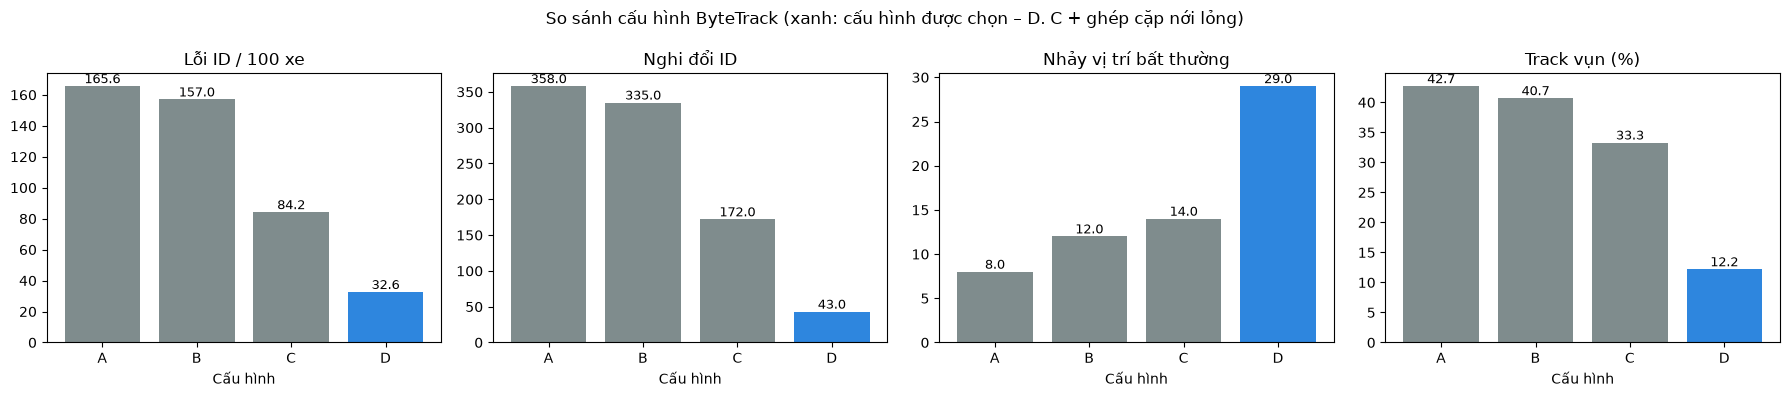

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
colors = ["#7f8c8d" if n != BEST else "#2e86de" for n in summary.index]
short = [n.split(".")[0] for n in summary.index]
for ax, col in zip(axes, ["Lỗi ID / 100 xe", "Nghi đổi ID", "Nhảy vị trí bất thường", "Track vụn (%)"]):
    bars = ax.bar(short, summary[col], color=colors)
    ax.bar_label(bars, fmt="%.1f", fontsize=9)
    ax.set_title(col)
    ax.set_xlabel("Cấu hình")
fig.suptitle(f"So sánh cấu hình ByteTrack (xanh: cấu hình được chọn – {BEST})")
fig.tight_layout()
fig.savefig(OUT_DIR / "so_sanh_cau_hinh.png", dpi=150)
plt.show()

## 5. Chạy toàn bộ video với cấu hình được chọn
Xuất video có vẽ box, `#ID lớp` và vệt di chuyển 1 giây gần nhất; mỗi ID một màu cố định nên **ID bị đổi sẽ thấy xe đổi màu**.

In [7]:
final_rows, final_runs = [], {}
for video in videos:
    n_frames = int(video_tbl.loc[video.name, "Số frame"])
    snaps = [int(n_frames * q) for q in (0.25, 0.5, 0.75)]
    out_path = OUT_DIR / f"{video.stem}_tracked.mp4"
    df, info = run_tracking(video, TRACKER_DIR / "bytetrack_tuned.yaml", writer_path=out_path, snapshot_frames=snaps)
    final_runs[video.name] = (df, info)
    df.to_csv(OUT_DIR / f"{video.stem}_tracks.csv", index=False)
    final_rows.append({"Video": video.name, **track_metrics(df, info)})
    print(f"{video.name}: {df.id.nunique()} ID -> {out_path}")
final_tbl = pd.DataFrame(final_rows).set_index("Video")
final_tbl.to_csv(OUT_DIR / "ket_qua_cau_hinh_chon.csv")
display(final_tbl)

FREE STOCK FOOTAGE - Heavy traffic.mp4: 221 ID -> output\FREE STOCK FOOTAGE - Heavy traffic_tracked.mp4


,Số ID,Độ dài track trung vị (giây),Track vụn (%),Nghi đổi ID,Nghi đổi ID / 100 ID,Nhảy vị trí bất thường,Nhảy bất thường / 100 ID,ID bị đổi lớp – trước làm mượt (%),ID bị đổi lớp – sau làm mượt (%),FPS xử lý
Video,,,,,,,,,,
FREE STOCK FOOTAGE - Heavy traffic.mp4,221,3.88,12.2,43,19.5,29,13.1,32.1,10.4,31.0


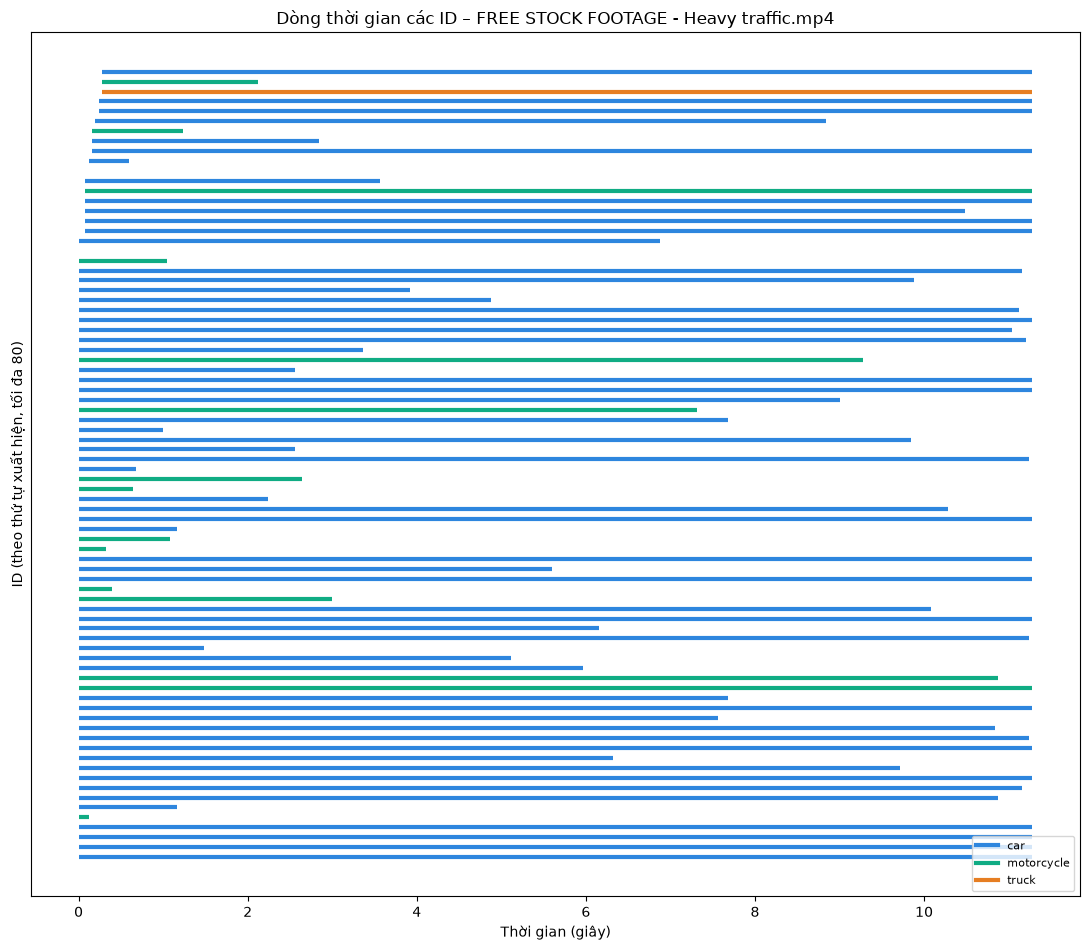

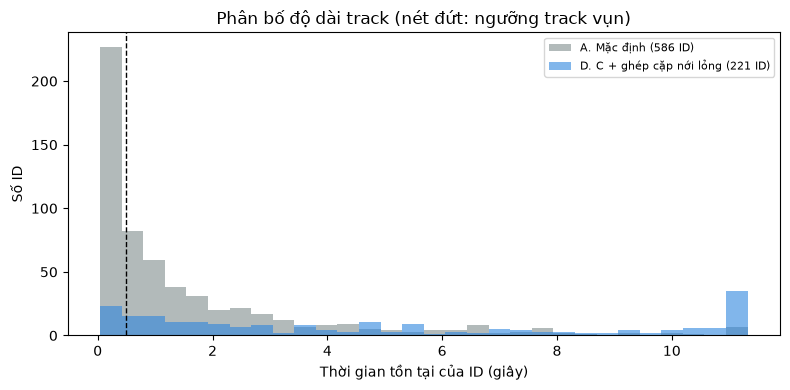

In [8]:
# Dòng thời gian các ID (video đầu tiên): mỗi dòng là một ID, từ lúc xuất hiện đến lúc mất
names = VehicleTracker(WEIGHTS).names
CLS_COLORS = ["#c0392b", "#2e86de", "#10ac84", "#e67e22", "#8e44ad", "#7f8c8d"]
first_video = videos[0].name
df, info = final_runs[first_video]
g = df.groupby("id")
tl = pd.DataFrame({"start": g.frame.min(), "end": g.frame.max(), "cls": g.cls.agg(lambda s: s.mode().iloc[0])})
tl = tl.sort_values("start").head(80)
fig, ax = plt.subplots(figsize=(11, max(3, len(tl) * 0.12)))
for i, (tid, r) in enumerate(tl.iterrows()):
    ax.hlines(i, r.start / info["fps_video"], r.end / info["fps_video"], color=CLS_COLORS[r.cls % 6], lw=3)
ax.set_yticks([])
ax.set_xlabel("Thời gian (giây)")
ax.set_ylabel(f"ID (theo thứ tự xuất hiện, tối đa {len(tl)})")
ax.legend(handles=[plt.Line2D([], [], color=CLS_COLORS[c % 6], lw=3, label=names[c]) for c in sorted(tl.cls.unique())],
          loc="lower right", fontsize=8)
ax.set_title(f"Dòng thời gian các ID – {first_video}")
fig.tight_layout()
fig.savefig(OUT_DIR / "dong_thoi_gian_id.png", dpi=150)
plt.show()

# Phân bố độ dài track: mặc định vs cấu hình được chọn (đoạn dùng để so sánh của video đầu tiên)
fig, ax = plt.subplots(figsize=(8, 4))
for name, color in [(DEFAULT, "#7f8c8d"), (BEST, "#2e86de")]:
    d, inf = tune_runs[(first_video, name)]
    if d.empty:
        continue
    spans = d.groupby("id").frame.agg(lambda s: s.max() - s.min() + 1) / inf["fps_video"]
    ax.hist(spans, bins=30, alpha=0.6, color=color, label=f"{name} ({len(spans)} ID)")
ax.axvline(MIN_TRACK_SECONDS, ls="--", color="k", lw=1)
ax.set_xlabel("Thời gian tồn tại của ID (giây)")
ax.set_ylabel("Số ID")
ax.set_title("Phân bố độ dài track (nét đứt: ngưỡng track vụn)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "do_dai_track.png", dpi=150)
plt.show()

## 6. Nhận xét từ việc xem video kết quả
Phần này **viết tay** sau khi xem video trong `output/` (ID có bị đổi khi xe bị che không, có gộp nhầm 2 xe thành 1 ID không…). Chỉ số "nhảy vị trí bất thường" chỉ bắt được ca gộp nhầm khi hai xe cách xa nhau, nên bước xem video vẫn cần thiết. Nếu đổi video hoặc model, hãy xem lại và sửa cho khớp.

In [9]:
# Nhận xét khi xem video "FREE STOCK FOOTAGE - Heavy traffic.mp4" với cấu hình D (ngày 01/11/2026)
QUAN_SAT = [
    "Phần lớn ô tô ở giữa khung hình giữ nguyên ID suốt video: ví dụ #1, #2, #3, #4, #55, #59, #65, #101, #119, "
    "#124, #163, #166, #171 giữ cùng ID từ frame 70 đến frame 141 (gần 3 giây); vệt di chuyển ngắn và liền mạch, "
    "đúng với cảnh xe nhích chậm khi kẹt xe.",
    "Vẫn có ca ID bị ghép nhầm sang xe khác: vệt di chuyển xuất hiện các đoạn thẳng dài vắt ngang khung hình, trong "
    "khi xe trong cảnh kẹt không thể di chuyển xa như vậy. Đây là cái giá của cấu hình D (ghép cặp nới lỏng): số lần "
    "nhảy vị trí bất thường tăng từ 8 (mặc định) lên 29, đổi lại số ca nghi đổi ID giảm từ 358 xuống 43.",
    "Một số box lớn trùm 2–4 xe (vd. #150, #185, #215). Đây là lỗi của bước nhận diện; tracker giữ một ID cho cả "
    "cụm, nên module đếm xe có thể đếm thiếu ở những chỗ này.",
    "Xe buýt thường bị gán nhãn car/truck (vd. #7 lúc là car, lúc là truck) và nhiều xe máy ở hàng đầu không được "
    "nhận diện, khớp với kết quả tuần 6 và 7 (lớp bus ít dữ liệu, xe máy bị che khuất). Đây là giới hạn của model "
    "nhận diện, ByteTrack không khắc phục được.",
    "Video chỉ dài 11 giây và được dùng cho cả bước chọn cấu hình lẫn đánh giá, nên kết quả có thể lạc quan; cần "
    "thêm video khác để kiểm tra lại cấu hình đã chọn.",
    "Đã thử thêm một video đường cao tốc phủ tuyết ở Bắc Mỹ (camera rất cao, xe nhỏ, có viền đen hai bên): model "
    "của dự án gần như không nhận diện được xe mà sinh box giả chiếm 42–46% khung hình, nên video này bị loại khỏi "
    "đánh giá (để ở videos/khong_phu_hop/). Model YOLO11s gốc (train trên COCO) vẫn nhận diện được xe trên video đó, "
    "cho thấy model của nhóm (train trên 135 ảnh) chưa khái quát được sang cảnh khác xa dữ liệu train.",
]

## 7. Sinh báo cáo Markdown

In [10]:
class MdReport:
    # Báo cáo Markdown: các mục, đoạn văn, bảng, ảnh được ghép thành từng dòng rồi ghi ra file .md
    def __init__(self):
        self.lines = []

    def add_heading(self, text, level=1):
        self.lines += ["#" * (level + 1) + " " + text, ""]

    def add_paragraph(self, text="", bold=False):
        self.lines += [f"**{text}**" if bold else text, ""]

    def add_code(self, text, lang="python"):
        self.lines += [f"```{lang}", text.strip("\n"), "```", ""]

    def save(self, path):
        Path(path).write_text("\n".join(self.lines), encoding="utf-8")


def fmt(v):
    if isinstance(v, (float, np.floating)):
        return "–" if np.isnan(v) else f"{v:.3f}".rstrip("0").rstrip(".")
    return str(v)


counter = {"Bảng": 0, "Hình": 0}


def caption(kind, text):
    counter[kind] += 1
    return f"{kind} {counter[kind]}. {text}"


def add_table(doc, df, title):
    doc.add_paragraph(caption("Bảng", title), bold=True)
    data = df.reset_index()
    doc.lines.append("| " + " | ".join(str(c) for c in data.columns) + " |")
    doc.lines.append("|" + "|".join(["---"] * len(data.columns)) + "|")
    for row in data.itertuples(index=False):
        doc.lines.append("| " + " | ".join(fmt(v).replace("|", "\\|") for v in row) + " |")
    doc.lines.append("")


def add_image(doc, path, title):
    # đường dẫn ảnh tương đối so với file báo cáo (cùng thư mục với notebook)
    if path is None or not Path(path).exists():
        return
    cap = caption("Hình", title)
    # bọc đường dẫn trong <> để tên file có khoảng trắng vẫn hiển thị được
    doc.lines += [f"![{cap}](<{Path(path).as_posix()}>)", "", f"*{cap}*", ""]


def bullets(doc, items):
    doc.lines += [f"- {s}" for s in items] + [""]


def change(col):
    a, b = summary.loc[DEFAULT, col], summary.loc[BEST, col]
    return f"{fmt(a)} → {fmt(b)}"


doc = MdReport()
doc.add_heading("BÁO CÁO TUẦN 8 – TÍCH HỢP BYTETRACK VỚI YOLO ĐỂ GÁN TRACKING ID", level=0)
bullets(doc, [
    "Người thực hiện: Đỗ Xuân Bách",
    f"Ngày: {datetime.now():%d/%m/%Y}",
    f"Model nhận diện: YOLO11s ({WEIGHTS.name}), chọn theo đề xuất của báo cáo tuần 7",
    f"Thuật toán theo dõi: ByteTrack (Ultralytics {ultralytics.__version__})",
    f"Phần cứng: GPU {GPU_NAME or 'không có'}",
])

doc.add_heading("1. Mục tiêu", level=1)
doc.add_paragraph(
    "Tích hợp thuật toán theo dõi đa đối tượng ByteTrack với model YOLO để mỗi xe trong video được gán một Tracking "
    "ID duy nhất và giữ nguyên ID đó trong suốt thời gian xuất hiện, kể cả khi bị xe khác che tạm thời. ID ổn định là "
    "điều kiện để module đếm xe qua vạch ảo không đếm trùng hoặc đếm sót.")

doc.add_heading("2. Phương pháp", level=1)
doc.add_heading("2.1. ByteTrack", level=2)
bullets(doc, [
    "Mỗi frame, YOLO phát hiện xe; ByteTrack dùng bộ lọc Kalman dự đoán vị trí mới của các track đang có.",
    f"Bước 1: các detection điểm cao (≥ track_high_thresh = {BASE['track_high_thresh']}) được ghép với track theo IoU.",
    f"Bước 2: các detection điểm thấp (≥ track_low_thresh = {BASE['track_low_thresh']}) được ghép với các track "
    "còn lại. Đây là điểm khác biệt của ByteTrack: xe bị che một phần thường có điểm thấp, nhưng vẫn được nối vào "
    "đúng ID thay vì bị bỏ.",
    "Detection điểm cao không ghép được (≥ new_track_thresh) tạo ID mới; track không được ghép sẽ được giữ "
    "track_buffer frame trước khi xóa, để nối lại nếu xe xuất hiện trở lại.",
])
doc.add_heading("2.2. Tích hợp", level=2)
bullets(doc, [
    "Module vehicle_tracker.py bọc model YOLO + ByteTrack thành lớp VehicleTracker: mỗi lần gọi update(frame) trả về "
    "danh sách xe gồm track_id, lớp, confidence, box và điểm neo (giữa cạnh dưới box).",
    "Detection được đưa vào tracker ở ngưỡng confidence 0.1 để ByteTrack có detection điểm thấp cho bước 2.",
    "Làm mượt lớp: lớp của mỗi ID lấy theo đa số trong 30 frame gần nhất, tránh một xe lúc là xe tải lúc là ô tô "
    "(lỗi nhầm lớp đã thấy ở tuần 6), giúp đếm xe theo loại chính xác hơn.",
])
doc.add_heading("2.3. Cách đánh giá", level=2)
doc.add_paragraph(
    "Video không có nhãn tracking chuẩn nên dùng các chỉ số gián tiếp: số ID, độ dài track trung vị, tỉ lệ track vụn "
    f"(ID tồn tại < {MIN_TRACK_SECONDS} giây), số ca nghi đổi ID (ID biến mất giữa khung hình và trong "
    f"{BREAK_GAP_SECONDS} giây có ID mới cùng lớp xuất hiện ngay gần đó – một xe bị gán nhiều ID), số lần nhảy vị trí "
    "bất thường (tâm box của một ID dịch xa hơn kích thước box giữa 2 lần xuất hiện – một ID bị ghép sang xe khác), "
    "tỉ lệ ID bị đổi lớp và tốc độ xử lý. Cấu hình được chọn theo tổng hai loại lỗi ID trên 100 xe ước lượng, vì "
    "giảm lỗi loại này bằng cách nới lỏng ghép cặp thường làm tăng lỗi loại kia. "
    f"Bốn cấu hình ByteTrack được so sánh trên tối đa {TUNE_MAX_SECONDS} giây đầu của mỗi video, sau đó cấu hình "
    "tốt nhất được chạy trên toàn bộ video và kiểm tra bằng mắt qua video kết quả.")

doc.add_heading("3. Dữ liệu", level=1)
add_table(doc, video_tbl, "Video dùng để đánh giá")

doc.add_heading("4. So sánh các cấu hình ByteTrack", level=1)
add_table(doc, cfg_tbl, "Tham số các cấu hình")
add_table(doc, summary, f"Kết quả các cấu hình (gộp {len(videos)} video, tối đa {TUNE_MAX_SECONDS} giây đầu mỗi video)")
if len(videos) > 1:
    add_table(doc, tune.set_index(["Video", "Cấu hình"]), "Kết quả các cấu hình theo từng video")
add_image(doc, OUT_DIR / "so_sanh_cau_hinh.png", "So sánh các cấu hình ByteTrack")
obs = [
    f"Cấu hình được chọn: {BEST} (tổng lỗi ID ít nhất). So với mặc định: lỗi ID / 100 xe "
    f"{change('Lỗi ID / 100 xe')}, nghi đổi ID {change('Nghi đổi ID')}, nhảy vị trí bất thường "
    f"{change('Nhảy vị trí bất thường')}, track vụn {change('Track vụn (%)')} %, số ID {change('Số ID')}, độ dài "
    f"track trung vị {change('Độ dài track trung vị (giây)')} giây.",
    f"Làm mượt lớp giảm tỉ lệ ID bị đổi lớp từ {fmt(summary.loc[BEST, 'ID bị đổi lớp – trước làm mượt (%)'])}% xuống "
    f"{fmt(summary.loc[BEST, 'ID bị đổi lớp – sau làm mượt (%)'])}%.",
]
if BEST == DEFAULT:
    obs.append("Cấu hình mặc định đã cho kết quả tốt nhất; các thay đổi thử nghiệm không cải thiện thêm trên video này.")
bullets(doc, obs)

doc.add_heading("5. Kết quả với cấu hình được chọn", level=1)
add_table(doc, final_tbl, "Kết quả trên toàn bộ video")
bullets(doc, [f"Video kết quả: [{p.name}](<{p.as_posix()}>)" for p in sorted(OUT_DIR.glob("*_tracked.mp4"))])
add_image(doc, OUT_DIR / "dong_thoi_gian_id.png", f"Dòng thời gian các ID – {first_video}")
add_image(doc, OUT_DIR / "do_dai_track.png", "Phân bố độ dài track: mặc định và cấu hình được chọn")
for p in sorted((OUT_DIR / "snapshots").glob("*.jpg"), key=lambda p: (p.stem.rsplit("_f", 1)[0], int(p.stem.rsplit("_f", 1)[1]))):
    add_image(doc, p, f"Frame {p.stem.rsplit('_f', 1)[1]} – {p.stem.rsplit('_f', 1)[0]}")
if QUAN_SAT:
    doc.add_paragraph("Quan sát từ video:", bold=True)
    bullets(doc, QUAN_SAT)

doc.add_heading("6. Hướng dẫn tích hợp cho nhóm", level=1)
doc.add_paragraph("Module nằm ở tuan8/vehicle_tracker.py, tự dùng model models/yolo11s_best.pt và cấu hình "
                  "tuan8/trackers/bytetrack_tuned.yaml.")
doc.add_paragraph("Luồng video camera (Phạm Văn Tường) – đọc frame bằng OpenCV và gọi update():", bold=True)
doc.add_code("""
import cv2
from vehicle_tracker import VehicleTracker, draw_tracks

tracker = VehicleTracker()
cap = cv2.VideoCapture(0)  # hoặc đường dẫn video / RTSP
while True:
    ok, frame = cap.read()
    if not ok:
        break
    tracks = tracker.update(frame)
    cv2.imshow("tracking", draw_tracks(frame, tracks))
    if cv2.waitKey(1) == 27:
        break
""")
doc.add_paragraph("Đếm xe qua vạch ảo (Nguyễn Thành Đạt) – dùng track_id và điểm neo để mỗi xe chỉ đếm một lần:", bold=True)
doc.add_code("""
from collections import Counter

LINE_Y = 400                 # vạch ngang ở y = 400 px
last_y, counted, counts = {}, set(), Counter()
# đoạn dưới đặt trong vòng lặp đọc frame
for t in tracker.update(frame):
    x, y = t.anchor          # điểm giữa cạnh dưới box
    prev = last_y.get(t.track_id)
    if prev is not None and prev < LINE_Y <= y and t.track_id not in counted:
        counted.add(t.track_id)
        counts[t.cls_name] += 1   # t.cls_name đã được làm mượt theo lịch sử ID
    last_y[t.track_id] = y
""")
doc.add_paragraph("Model ONNX (Nguyễn Vũ Tùng) – chỉ cần đổi đường dẫn model:", bold=True)
doc.add_code("""
tracker = VehicleTracker(weights="../models/yolo11s_best.onnx")
""")
doc.add_paragraph("Chạy nhanh từ dòng lệnh để xuất video có vẽ ID:", bold=True)
doc.add_code("python vehicle_tracker.py videos/ten_video.mp4 --out output/ten_video_tracked.mp4", lang="bash")

doc.add_heading("7. Hạn chế và lưu ý", level=1)
doc.add_heading("7.1. Hạn chế", level=2)
bullets(doc, [
    "Không có nhãn tracking chuẩn nên chưa tính được các chỉ số chuẩn như MOTA, IDF1, HOTA; các chỉ số gián tiếp "
    "chỉ phản ánh xu hướng.",
    "Chỉ số \"nghi đổi ID\" có thể đếm nhầm khi hai xe cùng lớp đi sát nhau; chỉ số \"nhảy vị trí bất thường\" chỉ "
    "bắt được ca gộp nhầm khi hai xe cách xa nhau, không bắt được khi ID chuyển sang xe ngay bên cạnh. Vì vậy vẫn "
    "cần xem video kết quả để kiểm tra.",
    f"Kết quả phụ thuộc video dùng để đánh giá ({len(videos)} video); góc quay, mật độ xe và độ phân giải khác có "
    "thể cần tinh chỉnh lại.",
    "ByteTrack chỉ dùng vị trí và IoU, không dùng đặc trưng hình ảnh, nên xe bị che hoàn toàn lâu hơn track_buffer "
    "sẽ bị gán ID mới khi xuất hiện lại.",
])
doc.add_heading("7.2. Lưu ý khi đọc và tái lập kết quả", level=2)
bullets(doc, [
    "FPS xử lý đo cho cả nhận diện và tracking, chưa gồm đọc/ghi video; dao động giữa các lần chạy như đã ghi ở "
    "báo cáo tuần 7.",
    "Video kết quả ghi bằng codec H.264 (avc1) nếu máy hỗ trợ, nếu không thì mp4v; nếu trình xem không mở được, "
    "dùng VLC.",
    "Phần \"Quan sát từ video\" (nếu có) được viết tay sau khi xem video kết quả; đổi video hoặc model thì cần cập nhật.",
    "Cách chạy lại: chép video vào tuan8/videos/, mở tuan8/tuần 8.ipynb, chọn kernel .venv của dự án rồi Run all. "
    "Notebook ghi đè trackers/bytetrack_tuned.yaml bằng cấu hình tốt nhất cho bộ video hiện có.",
])

doc.add_heading("Phụ lục: file đi kèm", level=1)
bullets(doc, ["vehicle_tracker.py – module theo dõi xe",
              "trackers/bytetrack_tuned.yaml – cấu hình được chọn; bytetrack_a…d.yaml – các cấu hình thử"]
        + [f"{OUT_DIR}/{p.name}" for p in sorted(OUT_DIR.glob("*.*"))]
        + [f"{OUT_DIR}/snapshots/ – ảnh chụp frame có vẽ ID"])

doc.save(REPORT_PATH)
print("Đã lưu báo cáo:", REPORT_PATH.resolve())

Đã lưu báo cáo: D:\ta\doxuanback\tuan8\Báo cáo tuần 8.md
